# Pipeline de Entrenamiento y Comparación de Modelos de Clasificación de Lengua de Señas (ASL)

Este notebook implementa el entrenamiento y la evaluación comparativa de tres modelos: un **CNN Baseline**, **MobileNetV2** y **EfficientNetB0**. Los dos modelos de transferencia se entrenan en dos fases (*Feature Extraction* y *Fine-Tuning*). Los hiperparámetros se leen de `baseline.yaml`, `mobilenetv2.yaml` y `efficientnetb0.yaml`.

Está pensado para ejecutarse **en local con GPU NVIDIA** (kernel `env_dl`).


In [ ]:
%pip install -q ultralytics opencv-python numpy pyyaml matplotlib

In [1]:
import os
import random
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from ultralytics import YOLO

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

# Habilitar memoria dinámica para evitar crash por OOM
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"GPU activada dinámicamente: {len(gpus)} GPU(s)")
    except RuntimeError as e:
        print(e)
else:
    print("No se detectó GPU disponible para TensorFlow.")

I0000 00:00:1794163558.623149    5151 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794163558.657426    5151 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794163559.534778    5151 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU activada dinámicamente: 1 GPU(s)


In [ ]:
import os
import cv2
import numpy as np
from ultralytics import YOLO

# 1. Cargar el modelo YOLOv8 para segmentación
print("[INFO] Cargando modelo YOLOv8 para segmentación...")
yolo_model = YOLO('yolov8n-seg.pt')

def segmentar_mano_con_yolo(image_path):
    """
    Detecta y segmenta la mano/persona usando YOLOv8-seg.
    Aplica la máscara binaria para aislar el objetivo sobre un fondo negro.
    Si no detecta máscara, retorna la imagen original.
    """
    img = cv2.imread(image_path)
    if img is None:
        return None

    h, w, _ = img.shape
    results = yolo_model(img, conf=0.15, verbose=False)
    mask_acumulada = np.zeros((h, w), dtype=np.uint8)

    for result in results:
        if result.masks is not None:
            masks = result.masks.data.cpu().numpy()
            classes = result.boxes.cls.cpu().numpy()

            for mask, cls in zip(masks, classes):
                if int(cls) == 0:  # Clase 0 = 'person' en COCO
                    mask_resized = cv2.resize(mask, (w, h))
                    mask_acumulada = cv2.bitwise_or(mask_acumulada, (mask_resized > 0.3).astype(np.uint8) * 255)

    if np.sum(mask_acumulada) == 0:
        return img

    img_segmentada = cv2.bitwise_and(img, img, mask=mask_acumulada)
    return img_segmentada

def preprocesar_dataset_con_yolo(directorio_origen, directorio_destino):
    """
    Recorre las subcarpetas de mis_fotos (A, B, C...), segmenta las imágenes
    con YOLO y guarda los resultados en mis_fotos_segmentadas.
    """
    print(f"[INFO] Iniciando segmentación del dataset de '{directorio_origen}' a '{directorio_destino}'...")

    procesadas = 0
    if not os.path.exists(directorio_origen):
        print(f"[ERROR] El directorio de origen '{directorio_origen}' no existe en esta ruta.")
        return

    for root, dirs, files in os.walk(directorio_origen):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                ruta_completa = os.path.join(root, file)
                ruta_relativa = os.path.relpath(ruta_completa, directorio_origen)
                ruta_salida = os.path.join(directorio_destino, ruta_relativa)

                os.makedirs(os.path.dirname(ruta_salida), exist_ok=True)

                img_seg = segmentar_mano_con_yolo(ruta_completa)
                if img_seg is not None:
                    cv2.imwrite(ruta_salida, img_seg)
                    procesadas += 1
                    if procesadas % 50 == 0:
                        print(f"[INFO] Imágenes procesadas: {procesadas}")

    print(f"[INFO] Procesamiento completado. Se guardaron {procesadas} imágenes en '{directorio_destino}'.")

# 2. Definición de rutas e inicio de ejecución
# Ruta absoluta apuntando a tu carpeta de Windows desde WSL2
ruta_base_windows = '/mnt/c/Users/Urmo04/Documents/IA2 Proyecto'

# Rutas de origen y destino utilizando la base
directorio_origen = os.path.join(ruta_base_windows, 'archive')
directorio_destino = os.path.join(ruta_base_windows, 'archive_segmentadas')

preprocesar_dataset_con_yolo(directorio_origen, directorio_destino)

### 1.2. Aumento de Datos Personalizado (Contraste Gamma, Rotación Sutil y Traslación)
Definimos un pipeline para generar exactamente 20000 imágenes aumentadas distribuidas uniformemente entre nuestras clases de entrenamiento.

In [2]:
import os
import random
import cv2
import numpy as np

def aplicar_gamma(image, gamma=1.0):
    """Ajusta el contraste usando corrección Gamma con OpenCV LUT."""
    inv_gamma = 1.0 / gamma
    # Aseguramos que la tabla sea uint8 y de forma (1, 256) o (256,)
    table = np.array([((i / 255.0) ** inv_gamma) * 255 for i in range(256)]).astype("uint8")
    return cv2.LUT(image, table)

def rotar_imagen(image, max_angle=10):
    """Rota la imagen un ángulo aleatorio en el rango [-max_angle, max_angle]."""
    angle = random.uniform(-max_angle, max_angle)
    h, w = image.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(image, M, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))

def trasladar_imagen(image, max_shift=12):
    """Desplaza la imagen aleatoriamente en los ejes X e Y."""
    tx = random.randint(-max_shift, max_shift)
    ty = random.randint(-max_shift, max_shift)
    h, w = image.shape[:2]
    M = np.float32([[1, 0, tx], [0, 1, ty]])
    return cv2.warpAffine(image, M, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))

def aumentar_imagen(image):
    """Aplica la secuencia de aumentaciones sutiles a la imagen."""
    # 1. Contraste Gamma
    gamma_val = random.uniform(0.6, 1.5)
    img_aug = aplicar_gamma(image, gamma=gamma_val)

    # 2. Rotación pequeña (máximo 10 grados)
    img_aug = rotar_imagen(img_aug, max_angle=10)

    # 3. Traslación en X e Y (máximo 12 píxeles)
    img_aug = trasladar_imagen(img_aug, max_shift=12)

    return img_aug

def generar_dataset_aumentado(directorio_origen, directorio_destino=None, total_imagenes_nuevas=20000):
    """
    Genera exactamente 'total_imagenes_nuevas' distribuidas equitativamente entre las clases.
    Si directorio_destino es None, guarda las imágenes en el mismo directorio de origen.
    """
    if not os.path.exists(directorio_origen):
        print(f"[ERROR] El directorio '{directorio_origen}' no existe.")
        return

    clases = [d for d in os.listdir(directorio_origen) if os.path.isdir(os.path.join(directorio_origen, d))]
    if not clases:
        print("[ERROR] No se encontraron carpetas de clases en el directorio especificado.")
        return

    num_clases = len(clases)
    imagenes_por_clase = total_imagenes_nuevas // num_clases
    sobrante = total_imagenes_nuevas % num_clases

    print(f"[INFO] Detectadas {num_clases} clases.")
    print(f"[INFO] Generando {imagenes_por_clase} imágenes nuevas por clase (Total objetivo: {total_imagenes_nuevas}).")

    total_generadas = 0

    for idx, clase in enumerate(clases):
        clase_path_origen = os.path.join(directorio_origen, clase)
        clase_path_destino = os.path.join(directorio_destino, clase) if directorio_destino else clase_path_origen

        os.makedirs(clase_path_destino, exist_ok=True)

        # Filtrar solo archivos originales (ignorar archivos generados previamente si se guarda en la misma carpeta)
        archivos = [
            f for f in os.listdir(clase_path_origen)
            if f.lower().endswith(('.png', '.jpg', '.jpeg')) and not f.startswith('aug_')
        ]

        if not archivos:
            print(f"[WARN] No hay imágenes originales en la carpeta {clase}. Saltando...")
            continue

        a_generar = imagenes_por_clase + (1 if idx < sobrante else 0)

        for i in range(a_generar):
            img_elegida = random.choice(archivos)
            img_path = os.path.join(clase_path_origen, img_elegida)

            img = cv2.imread(img_path)
            if img is not None:
                img_aug = aumentar_imagen(img)

                nombre_salida = f"aug_{total_generadas}_{img_elegida}"
                cv2.imwrite(os.path.join(clase_path_destino, nombre_salida), img_aug)
                total_generadas += 1

    print(f"[INFO] ¡Aumento de datos finalizado! Se crearon {total_generadas} imágenes aumentadas con éxito.")



In [ ]:
# --- EJECUCIÓN CON RUTAS RELATIVAS LOCALES ---
# Opción A: Guardar las imágenes aumentadas dentro de la misma carpeta de las fotos segmentadas
directorio_segmentadas = './archive_segmentadas/asl_alphabet_train/asl_alphabet_train'
generar_dataset_aumentado(directorio_segmentadas, total_imagenes_nuevas=20000)

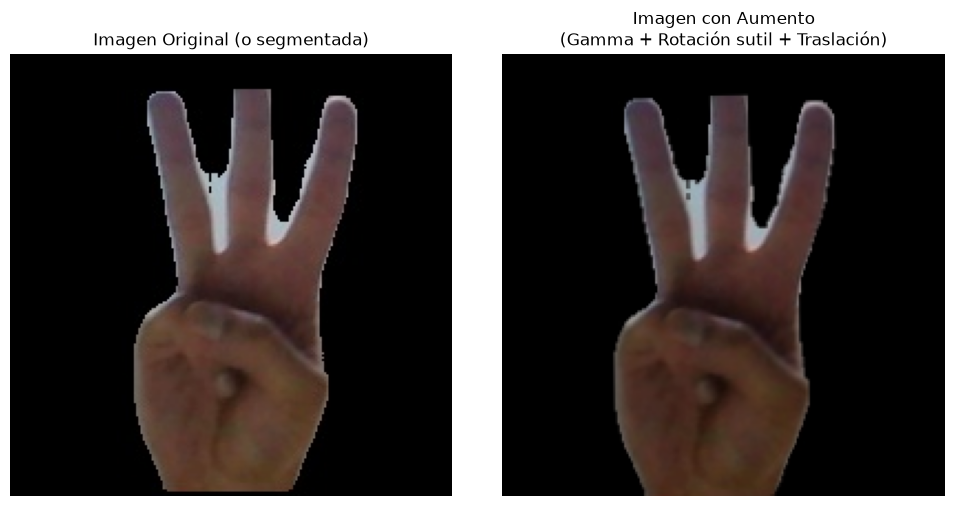

In [3]:
# Visualizar una muestra del pipeline de aumento de datos
import matplotlib.pyplot as plt
import glob

def visualizar_aumento_ejemplo(directorio_train):
    # Intentar buscar una imagen real en la carpeta de entrenamiento
    patron = os.path.join(directorio_train, "**", "*.*")
    archivos = [f for f in glob.glob(patron, recursive=True) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if not archivos:
        # Si no hay imágenes en la ruta, generamos una imagen sintética de prueba
        print("[WARN] No se encontraron imágenes en el directorio. Creando una imagen de muestra artificial...")
        img_original = np.zeros((224, 224, 3), dtype=np.uint8)
        cv2.putText(img_original, 'Mano ASL', (20, 110), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 2)
        # Dibujar una figura geométrica simple como simulador de mano
        cv2.rectangle(img_original, (80, 80), (140, 180), (0, 255, 0), -1)
    else:
        ruta_muestra = random.choice(archivos)
        img_original = cv2.imread(ruta_muestra)

    # Aplicar el aumento de datos
    img_aumentada = aumentar_imagen(img_original)

    # Convertir de BGR a RGB para mostrar correctamente con Matplotlib
    img_original_rgb = cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB)
    img_aumentada_rgb = cv2.cvtColor(img_aumentada, cv2.COLOR_BGR2RGB)

    # Dibujar las imágenes
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img_original_rgb)
    plt.title("Imagen Original (o segmentada)")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(img_aumentada_rgb)
    plt.title("Imagen con Aumento\n(Gamma + Rotación sutil + Traslación)")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

# Ejecutar demostración (puedes cambiar TRAIN_DIR según tu ruta actual)
try:
    visualizar_aumento_ejemplo(TRAIN_DIR)
except NameError:
    # Fallback si aún no se ejecutan las celdas de rutas
    visualizar_aumento_ejemplo('./archive_segmentadas/asl_alphabet_train/asl_alphabet_train')

## 1. Configuración del Entorno e Importación de Librerías

In [4]:
# ===================================================================== #
#   1. IMPORTACIONES GLOBALES, CONFIGURACIÓN Y CARGA DE MODELOS (.YAML)  #
# ===================================================================== #

import os
import gc
import sys
import platform
import subprocess
import yaml
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.applications import MobileNetV2, EfficientNetB0
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess

# --- CONFIGURACIÓN DE GPU LOCAL PARA EVITAR CRASH DEL DRIVER ---
os.environ['TF_XLA_FLAGS'] = '--tf_xla_enable_xla_devices=false'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['CUDA_VISIBLE_DEVICES'] = '0'  # Asegurar uso de GPU principal

# Carga perezosa/segura de dependencias opcionales
try:
    import matplotlib
    import matplotlib.pyplot as plt
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    import matplotlib.pyplot as plt

try:
    import cv2
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "opencv-python"])
    import cv2

try:
    from ultralytics import YOLO
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
    from ultralytics import YOLO

# --- Verificación de Hardware ---
os_type = platform.system()
print(f"[INFO] Sistema Operativo: {os_type}")
print(f"[INFO] Versión de TensorFlow: {tf.__version__}")

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"[INFO] GPU Detectada: {gpus}")
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("[INFO] Crecimiento de memoria activado.")
    except Exception as e:
        print(f"[WARN] No se pudo asignar crecimiento de memoria: {e}")
else:
    print("[WARN] No se detectó GPU activa para TensorFlow.")

# --- Carga de Configuraciones YAML ---
CONFIG_PATHS = {
    'baseline': './baseline.yaml',
    'efficientnetb0': './efficientnetb0.yaml',
    'mobilenetv2': './mobilenetv2.yaml'
}

model_configs = {}
for model_name, path in CONFIG_PATHS.items():
    if os.path.exists(path):
        with open(path, 'r', encoding='utf-8') as file:
            model_configs[model_name] = yaml.safe_load(file)
        print(f"[ÉXITO] Configuración de '{model_name}' cargada.")
    else:
        print(f"[WARN] Archivo no encontrado: {path}")

[INFO] Sistema Operativo: Linux
[INFO] Versión de TensorFlow: 2.21.0
[INFO] GPU Detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
[INFO] Crecimiento de memoria activado.
[ÉXITO] Configuración de 'baseline' cargada.
[ÉXITO] Configuración de 'efficientnetb0' cargada.
[ÉXITO] Configuración de 'mobilenetv2' cargada.


In [5]:
# ===================================================================== #
#   1.2. COMPARATIVA DE CONFIGURACIONES EXPERIMENTALES (YAMLS)          #
# ===================================================================== #

import os
import yaml

# Asegurar que las configuraciones estén cargadas incluso si no se ejecutó la celda anterior
try:
    model_configs
except NameError:
    print("[INFO] 'model_configs' no estaba definido en el kernel. Cargando configuraciones de emergencia...")
    CONFIG_PATHS = {
        'baseline': './baseline.yaml',
        'efficientnetb0': './efficientnetb0.yaml',
        'mobilenetv2': './mobilenetv2.yaml'
    }
    model_configs = {}
    for model_name, path in CONFIG_PATHS.items():
        if os.path.exists(path):
            with open(path, 'r', encoding='utf-8') as file:
                model_configs[model_name] = yaml.safe_load(file)
            print(f"  -> '{model_name}' cargado con éxito.")
        else:
            print(f"  -> [WARN] No se encontró el archivo: {path}")

print("\n=== COMPARATIVA DE PARÁMETROS EXPERIMENTALES ===\n")
for model_name, config in model_configs.items():
    print(f"🔹 Modelo: {model_name.upper()}")
    if isinstance(config, dict):
        for key, value in config.items():
            print(f"  - {key}: {value}")
    else:
        print(f"  - Contenido crudo: {config}")
    print("-" * 40)


=== COMPARATIVA DE PARÁMETROS EXPERIMENTALES ===

🔹 Modelo: BASELINE
  - data: {'raw_dir': 'data/raw/asl_alphabet_train/asl_alphabet_train', 'split': {'train': 0.7, 'val': 0.15, 'test': 0.15}, 'seed': 42, 'img_size': [128, 128], 'batch_size': 64}
  - model: {'filters': [32, 64, 128, 256], 'dense_units': 128, 'dropout': 0.4}
  - train: {'epochs': 30, 'learning_rate': 0.0001, 'mixed_precision': True, 'monitor': 'val_accuracy', 'early_stopping_patience': 6, 'reduce_lr_patience': 2}
----------------------------------------
🔹 Modelo: EFFICIENTNETB0
  - data: {'raw_dir': 'data/raw/asl_alphabet_train/asl_alphabet_train', 'split': {'train': 0.7, 'val': 0.15, 'test': 0.15}, 'seed': 42, 'img_size': [128, 128], 'batch_size': 64}
  - model: {'name': 'efficientnetb0', 'weights': 'imagenet', 'dropout': 0.3}
  - train: {'epochs_head': 3, 'epochs_finetune': 12, 'lr_head': 0.001, 'lr_finetune': 5e-05, 'unfreeze_layers': 40, 'mixed_precision': True, 'monitor': 'val_accuracy', 'early_stopping_patience':

## 2. Parámetros Globales y Carga de Datos

El dataset (ya segmentado y aumentado) se lee de la carpeta local indicada en `DATASET_DIR`.


In [6]:
# ========================================== #
#   2. PARÁMETROS GLOBALES Y CARGA DE DATOS   #
# ========================================== #

tf.keras.backend.clear_session()
gc.collect()

# Habilitar precisión mixta de forma segura
from tensorflow.keras import mixed_precision
try:
    policy = mixed_precision.Policy('mixed_float16')
    mixed_precision.set_global_policy(policy)
    print("[INFO] Precisión mixta activa para optimización de VRAM.")
except Exception as e:
    print(f"[WARN] Omitiendo precisión mixta: {e}")

base_config = model_configs.get('baseline', {})
data_config = base_config.get('data', {})

IMG_SIZE = tuple(data_config.get('img_size', [128, 128]))
BATCH_SIZE = 32
NUM_CLASSES = 29
DATASET_DIR = './archive_segmentadas/asl_alphabet_train/asl_alphabet_train'

print(f"[INFO] Configuración activa:")
print(f"   - Ruta: {DATASET_DIR}")
print(f"   - Resolución: {IMG_SIZE}")
print(f"   - Batch Size: {BATCH_SIZE}")

def cargar_datasets_con_split(dataset_dir, img_size, batch_size):
    if not os.path.exists(dataset_dir):
        raise FileNotFoundError(f"Directorio ausente: {os.path.abspath(dataset_dir)}")

    print(f"[INFO] Leyendo imágenes del disco local...")

    train_ds = tf.keras.utils.image_dataset_from_directory(
        dataset_dir,
        validation_split=0.3,
        subset="training",
        seed=42,
        image_size=img_size,
        batch_size=batch_size,
        label_mode='categorical',
        shuffle=True
    )

    temp_val_test_ds = tf.keras.utils.image_dataset_from_directory(
        dataset_dir,
        validation_split=0.3,
        subset="validation",
        seed=42,
        image_size=img_size,
        batch_size=batch_size,
        label_mode='categorical',
        shuffle=True
    )

    val_batches = tf.data.experimental.cardinality(temp_val_test_ds).numpy() // 2
    if val_batches == 0:
        val_batches = 1

    val_ds = temp_val_test_ds.take(val_batches)
    test_ds = temp_val_test_ds.skip(val_batches)

    def cast_inputs(images, labels):
        return tf.cast(images, tf.float32), labels

    train_ds = train_ds.map(cast_inputs, num_parallel_calls=tf.data.AUTOTUNE)
    val_ds = val_ds.map(cast_inputs, num_parallel_calls=tf.data.AUTOTUNE)
    test_ds = test_ds.map(cast_inputs, num_parallel_calls=tf.data.AUTOTUNE)

    return train_ds, val_ds, test_ds

[INFO] Precisión mixta activa para optimización de VRAM.
[INFO] Configuración activa:
   - Ruta: ./archive_segmentadas/asl_alphabet_train/asl_alphabet_train
   - Resolución: (128, 128)
   - Batch Size: 32


## 3. Construcción Dinámica de Modelos (2 Fases)

Aplicamos preprocesamiento según la arquitectura especificando su respectivo escalado de entradas (`preprocess_input`).

In [7]:
# ===================================================================== #
#   3. FÁBRICA DE MODELOS (SOPORTA BASELINE, MOBILENETV2 Y EFFICIENTNET) #
# ===================================================================== #

def build_model(architecture_name, img_size=(128, 128), num_classes=29):

    config = model_configs.get(architecture_name, {})
    inputs = layers.Input(shape=(img_size[0], img_size[1], 3))

    if architecture_name == 'baseline':
        # Modelo personalizado CNN Baseline
        m_config = config.get('model', {})
        x = inputs
        # Capa de reescalado simple para el baseline
        x = layers.Rescaling(1./255)(x)

        # Agregar bloques convolucionales dinámicamente de acuerdo a los filtros del .yaml
        for filters in m_config.get('filters', [32, 64, 128, 256]):
            x = layers.Conv2D(filters, (3, 3), activation='relu', padding='same')(x)
            x = layers.BatchNormalization()(x)
            x = layers.MaxPooling2D((2, 2))(x)

        x = layers.Flatten()(x)
        x = layers.Dense(m_config.get('dense_units', 128), activation='relu')(x)
        x = layers.Dropout(m_config.get('dropout', 0.4))(x)
        outputs = layers.Dense(num_classes, activation='softmax', dtype='float32')(x)  # float32 por precisión mixta

        model = models.Model(inputs=inputs, outputs=outputs, name="Baseline_ASL")
        return model, None

    elif architecture_name == 'mobilenetv2':
        m_config = config.get('model', {})
        x = mobilenet_preprocess(inputs)
        base_model = MobileNetV2(input_shape=(img_size[0], img_size[1], 3),
                                  include_top=False,
                                  weights=m_config.get('weights', 'imagenet'))
        base_model.trainable = False
        x = base_model(x, training=False)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dropout(m_config.get('dropout', 0.3))(x)
        outputs = layers.Dense(num_classes, activation='softmax', dtype='float32')(x)  # float32 por precisión mixta

        model = models.Model(inputs=inputs, outputs=outputs, name="MobileNetV2_ASL")
        return model, base_model

    elif architecture_name == 'efficientnetb0':
        m_config = config.get('model', {})
        x = efficientnet_preprocess(inputs)
        base_model = EfficientNetB0(input_shape=(img_size[0], img_size[1], 3),
                                     include_top=False,
                                     weights=m_config.get('weights', 'imagenet'))
        base_model.trainable = False
        x = base_model(x, training=False)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dropout(m_config.get('dropout', 0.3))(x)
        outputs = layers.Dense(num_classes, activation='softmax', dtype='float32')(x)  # float32 por precisión mixta

        model = models.Model(inputs=inputs, outputs=outputs, name="EfficientNetB0_ASL")
        return model, base_model

    else:
        raise ValueError(f"Arquitectura no soportada: {architecture_name}")

print("[INFO] Fábrica de modelos integrada para Baseline, MobileNetV2 y EfficientNetB0.")

[INFO] Fábrica de modelos integrada para Baseline, MobileNetV2 y EfficientNetB0.


## 4. Pipeline de Entrenamiento en Dos Fases

In [8]:
def entrenar_modelo_config(architecture_name, train_ds, val_ds, img_size=None, num_classes=None):
    """
    Entrena un modelo usando los hiperparámetros de su YAML.
      - baseline: una sola fase.
      - mobilenetv2 / efficientnetb0: Fase 1 (base congelada) + Fase 2 (fine-tuning de las últimas capas).
    Devuelve (modelo, historial) con claves 'acc', 'val_acc', 'loss', 'val_loss'.
    """
    cfg = model_configs.get(architecture_name)
    if not cfg:
        raise ValueError(f"No hay configuración YAML cargada para '{architecture_name}'.")
    t = cfg.get('train', {})
    img_size = img_size or IMG_SIZE
    num_classes = num_classes or NUM_CLASSES

    print(f"\n{'='*50}")
    print(f" INICIANDO ENTRENAMIENTO: {architecture_name.upper()}")
    print(f"{'='*50}\n")

    model, base_model = build_model(architecture_name, img_size, num_classes)
    monitor = t.get('monitor', 'val_accuracy')
    mode = 'max' if 'acc' in monitor else 'min'
    es_patience = t.get('early_stopping_patience', 4)
    lr_patience = t.get('reduce_lr_patience', 2)

    def make_callbacks(extra=None):
        cbs = [
            EarlyStopping(monitor=monitor, mode=mode, patience=es_patience, restore_best_weights=True),
            ReduceLROnPlateau(monitor=monitor, mode=mode, factor=0.2, patience=lr_patience, min_lr=1e-7),
        ]
        return cbs + (extra or [])

    def run_fit(epochs, lr, callbacks_list):
        model.compile(optimizer=optimizers.Adam(learning_rate=lr),
                      loss='categorical_crossentropy', metrics=['accuracy'],
                      jit_compile=False)  # evita el autotuner de XLA/cuDNN que fallaba en tu GPU
        return model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks_list)

    checkpoint = ModelCheckpoint(f"best_{architecture_name}_model.keras", monitor=monitor,
                                 mode=mode, save_best_only=True, verbose=1)

    if base_model is None:
        # --- BASELINE: una sola fase ---
        print("[BASELINE] Entrenamiento completo desde cero...")
        histories_list = [run_fit(t.get('epochs', 30), t.get('learning_rate', 1e-3), make_callbacks([checkpoint]))]
    else:
        # --- FASE 1: FEATURE EXTRACTION ---
        print("[FASE 1] Extracción de características (base congelada)...")
        h1 = run_fit(t.get('epochs_head', 3), t.get('lr_head', 1e-3), make_callbacks())

        # --- FASE 2: FINE-TUNING ---
        n_unfreeze = t.get('unfreeze_layers', 30)
        print(f"\n[FASE 2] Fine-Tuning (descongelando las últimas {n_unfreeze} capas)...")
        base_model.trainable = True
        for layer in base_model.layers[:-n_unfreeze]:
            layer.trainable = False
        # Mantener BatchNorm congelada para no desestabilizar los pesos preentrenados
        for layer in base_model.layers:
            if isinstance(layer, layers.BatchNormalization):
                layer.trainable = False

        h2 = run_fit(t.get('epochs_finetune', 12), t.get('lr_finetune', 5e-5), make_callbacks([checkpoint]))
        histories_list = [h1, h2]

    def juntar(key):
        out = []
        for h in histories_list:
            out += h.history[key]
        return out

    combined_history = {
        'acc': juntar('accuracy'),
        'val_acc': juntar('val_accuracy'),
        'loss': juntar('loss'),
        'val_loss': juntar('val_loss'),
    }
    return model, combined_history


## 5. Visualización y Evaluación Comparativa

In [9]:
def plot_comparison(histories):
    """Genera gráficas comparativas de Exactitud y Pérdida."""
    plt.figure(figsize=(14, 5))

    # Gráfica de Precisión (Accuracy)
    plt.subplot(1, 2, 1)
    for name, hist in histories.items():
        plt.plot(hist['val_acc'], label=f'{name} (Val Acc)')
    plt.title('Comparativa de exactitud en Validación')
    plt.xlabel('Época Total')
    plt.ylabel('Exactitud (Accuracy)')
    plt.legend()
    plt.grid(True)

    # Gráfica de Pérdida (Loss)
    plt.subplot(1, 2, 2)
    for name, hist in histories.items():
        plt.plot(hist['val_loss'], label=f'{name} (Val Loss)')
    plt.title('Comparativa de pérdida en Validación')
    plt.xlabel('Época Total')
    plt.ylabel('Pérdida (Loss)')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

Clases: 29 ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']
Media de píxeles: 59.91786575317383 | máx: 255.0


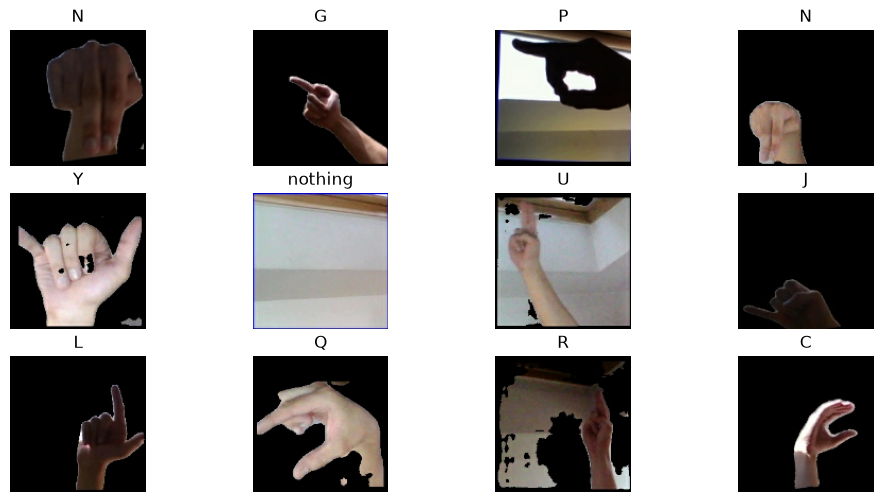

In [11]:
import matplotlib.pyplot as plt, numpy as np
class_names = sorted(os.listdir(DATASET_DIR))
print("Clases:", len(class_names), class_names)

imgs, lbls = next(iter(train_ds))
print("Media de píxeles:", float(tf.reduce_mean(imgs)), "| máx:", float(tf.reduce_max(imgs)))

plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(3, 4, i+1)
    plt.imshow(imgs[i].numpy().astype("uint8"))
    plt.title(class_names[int(tf.argmax(lbls[i]))])
    plt.axis("off")
plt.show()

## 6. Ejecución Completa del Experimento

[INFO] Leyendo imágenes del disco local...
Found 112179 files belonging to 29 classes.
Using 78526 files for training.


I0000 00:00:1794163591.835964    5151 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Found 112179 files belonging to 29 classes.
Using 33653 files for validation.
[INFO] Dataset validado. Forma del batch de imágenes: (32, 128, 128, 3), Etiquetas: (32, 29)

 INICIANDO ENTRENAMIENTO: BASELINE

[BASELINE] Entrenamiento completo desde cero...
Epoch 1/30


/home/uriel/env_dl/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1794163602.347490    5151 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.
I0000 00:00:1794163602.444699    5264 cuda_dnn.cc:461] Loaded cuDNN version 92801


2454/2454 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.4655 - loss: 1.8513
Epoch 1: val_accuracy improved from None to 0.80086, saving model to best_baseline_model.keras

Epoch 1: finished saving model to best_baseline_model.keras
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 164s 65ms/step - accuracy: 0.4655 - loss: 1.8513 - val_accuracy: 0.8009 - val_loss: 0.6598 - learning_rate: 1.0000e-04
Epoch 2/30
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.8072 - loss: 0.6102
Epoch 2: val_accuracy improved from 0.80086 to 0.94760, saving model to best_baseline_model.keras

Epoch 2: finished saving model to best_baseline_model.keras
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 155s 63ms/step - accuracy: 0.8072 - loss: 0.6102 - val_accuracy: 0.9476 - val_loss: 0.1697 - learning_rate: 1.0000e-04
Epoch 3/30
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.9097 - loss: 0.2762
Epoch 3: val_accuracy improved from 0.94760 to 0.96328, saving model to best_baseline_model.keras

Epoch 3: finished saving model

W0000 00:00:1794168684.633702    5255 bfc_allocator.cc:383] Garbage collection: deallocate free memory regions (i.e., allocations) so that we can re-allocate a larger region to avoid OOM due to memory fragmentation. If you see this message frequently, you are running near the threshold of the available device memory and re-allocation may incur great performance overhead. You may try smaller batch sizes to observe the performance impact. Set TF_ENABLE_GPU_GARBAGE_COLLECTION=false if you'd like to disable this feature.


2454/2454 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.9482 - loss: 0.1632
Epoch 1: val_accuracy improved from None to 0.97523, saving model to best_mobilenetv2_model.keras

Epoch 1: finished saving model to best_mobilenetv2_model.keras
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 135s 52ms/step - accuracy: 0.9482 - loss: 0.1632 - val_accuracy: 0.9752 - val_loss: 0.0788 - learning_rate: 5.0000e-05
Epoch 2/12
2453/2454 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.9791 - loss: 0.0628
Epoch 2: val_accuracy improved from 0.97523 to 0.98408, saving model to best_mobilenetv2_model.keras

Epoch 2: finished saving model to best_mobilenetv2_model.keras
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 127s 52ms/step - accuracy: 0.9791 - loss: 0.0628 - val_accuracy: 0.9841 - val_loss: 0.0526 - learning_rate: 5.0000e-05
Epoch 3/12
2453/2454 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9868 - loss: 0.0391
Epoch 3: val_accuracy did not improve from 0.98408
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 127s 52ms/step - accuracy: 0.9868 -

E0000 00:00:1794170676.925241    5151 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_ASL_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


2454/2454 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.9598 - loss: 0.1233
Epoch 1: val_accuracy improved from None to 0.98942, saving model to best_efficientnetb0_model.keras

Epoch 1: finished saving model to best_efficientnetb0_model.keras
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 181s 70ms/step - accuracy: 0.9598 - loss: 0.1233 - val_accuracy: 0.9894 - val_loss: 0.0372 - learning_rate: 5.0000e-05
Epoch 2/12
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.9831 - loss: 0.0525
Epoch 2: val_accuracy improved from 0.98942 to 0.99275, saving model to best_efficientnetb0_model.keras

Epoch 2: finished saving model to best_efficientnetb0_model.keras
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 169s 69ms/step - accuracy: 0.9831 - loss: 0.0525 - val_accuracy: 0.9928 - val_loss: 0.0238 - learning_rate: 5.0000e-05
Epoch 3/12
2454/2454 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.9897 - loss: 0.0324
Epoch 3: val_accuracy improved from 0.99275 to 0.99489, saving model to best_efficientnetb0_model.keras



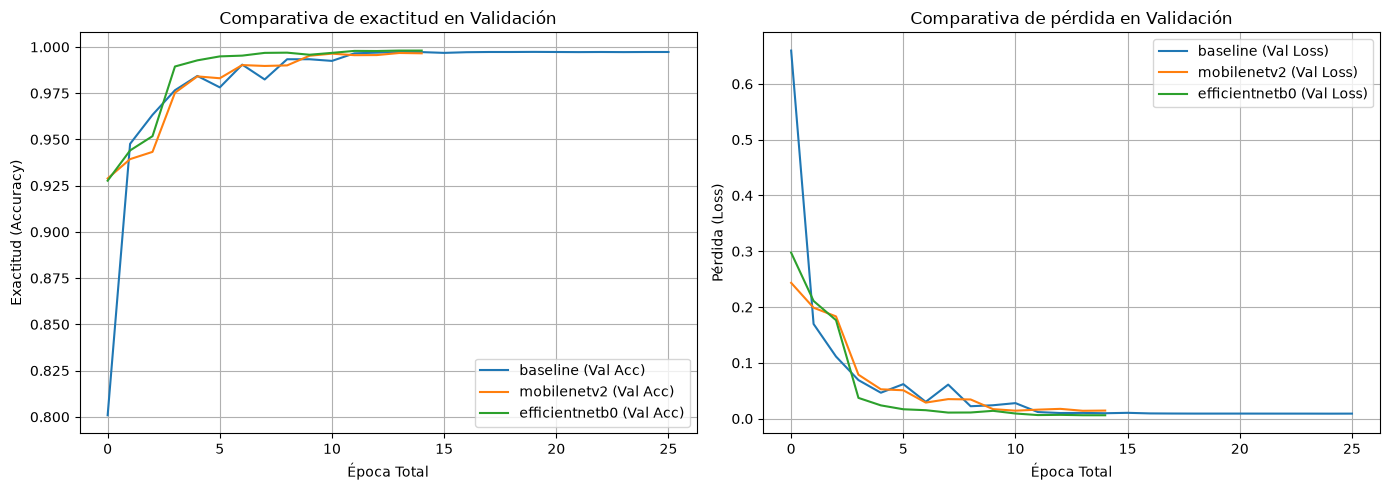


 RESULTADOS COMPARATIVOS FINALES
BASELINE        -> Test Loss: 0.0107, Test Accuracy: 0.9973
MOBILENETV2     -> Test Loss: 0.0173, Test Accuracy: 0.9955
EFFICIENTNETB0  -> Test Loss: 0.0056, Test Accuracy: 0.9982


In [10]:
# ===================================================================== #
#   4. PIPELINE UNIFICADO Y EJECUCIÓN COMPARATIVA DE LOS 3 MODELOS      #
# ===================================================================== #

import tensorflow as tf
import gc
import traceback

# --- Carga y validación estricta de Datasets ---
train_ds, val_ds, test_ds = cargar_datasets_con_split(DATASET_DIR, IMG_SIZE, BATCH_SIZE)

# Verificación de tipo para evitar errores de TypeSpec con arreglos de rutas en texto
if not isinstance(train_ds, tf.data.Dataset):
    raise TypeError(
        f"[ERROR CRÍTICO] cargar_datasets_con_split devolvió {type(train_ds)} en lugar de tf.data.Dataset. "
        "Asegúrate de usar tf.keras.utils.image_dataset_from_directory dentro de la función del Bloque 2."
    )

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# Probar el primer batch para confirmar tensores en memoria antes del entrenamiento
for sample_img, sample_lbl in train_ds.take(1):
    print(f"[INFO] Dataset validado. Forma del batch de imágenes: {sample_img.shape}, Etiquetas: {sample_lbl.shape}")

histories = {}
evaluaciones = {}

for mod in ['baseline', 'mobilenetv2', 'efficientnetb0']:
    try:
        model_trained, hist = entrenar_modelo_config(mod, train_ds, val_ds)
        histories[mod] = hist

        print(f"\n[INFO] Evaluando {mod.upper()} en el Test Set...")
        loss, acc = model_trained.evaluate(test_ds, verbose=1)
        evaluaciones[mod] = (loss, acc)

        # Liberación completa de la VRAM y memoria de la sesión
        del model_trained
        tf.keras.backend.clear_session()
        gc.collect()
        print(f"[INFO] Recursos de GPU y RAM liberados después de entrenar {mod.upper()}.\n")
    except Exception as e:
        print(f"[ERROR] Error entrenando {mod}: {e}")
        traceback.print_exc()

# --- Gráfica comparativa final ---
try:
    plot_comparison(histories)
except Exception as e:
    print(f"[WARN] No se pudo generar el gráfico comparativo: {e}")

print("\n" + "="*50)
print(" RESULTADOS COMPARATIVOS FINALES")
print("="*50)
for mod, eval_res in evaluaciones.items():
    print(f"{mod.upper():15} -> Test Loss: {eval_res[0]:.4f}, Test Accuracy: {eval_res[1]:.4f}")

/home/uriel/env_dl/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 42 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(store)


=== ENTRENAMIENTO Y VALIDACIÓN ===


,Modelo,Épocas ejecutadas,Mejor época,Train accuracy,Train loss,Val accuracy,Val loss
0,baseline,26,20,0.9986,0.0041,0.9973,0.0091
1,mobilenetv2,15,14,0.9999,0.0004,0.9967,0.0141
2,efficientnetb0,15,14,0.9988,0.0039,0.9980,0.0061



=== TEST ===


,Modelo,Test accuracy,Test loss,F1 macro,Inferencia (ms/imagen),Parámetros (M)
0,baseline,0.9973,0.0102,0.9973,0.498,2.49
1,mobilenetv2,0.9955,0.0173,0.9955,0.848,2.30
2,efficientnetb0,0.9982,0.0056,0.9982,1.163,4.09


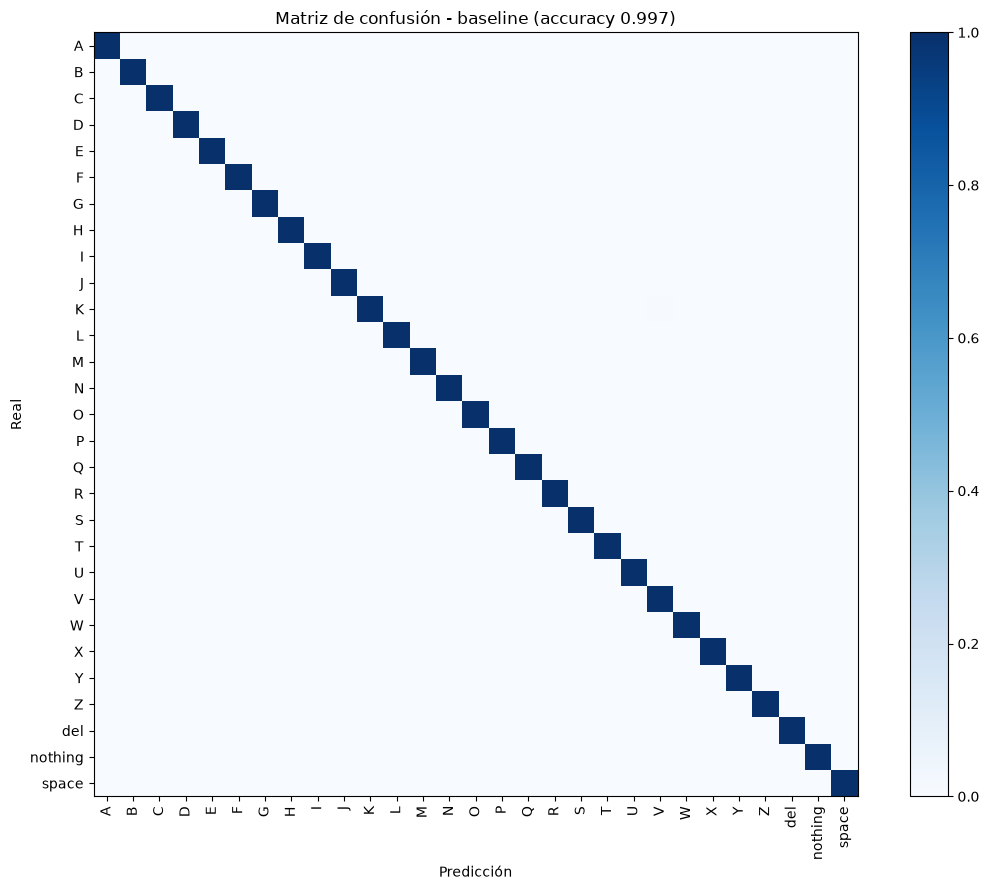

Confusiones más frecuentes en baseline:
   K -> V: 2 veces
   Z -> S: 2 veces
   X -> S: 2 veces
   W -> V: 2 veces
   G -> H: 2 veces


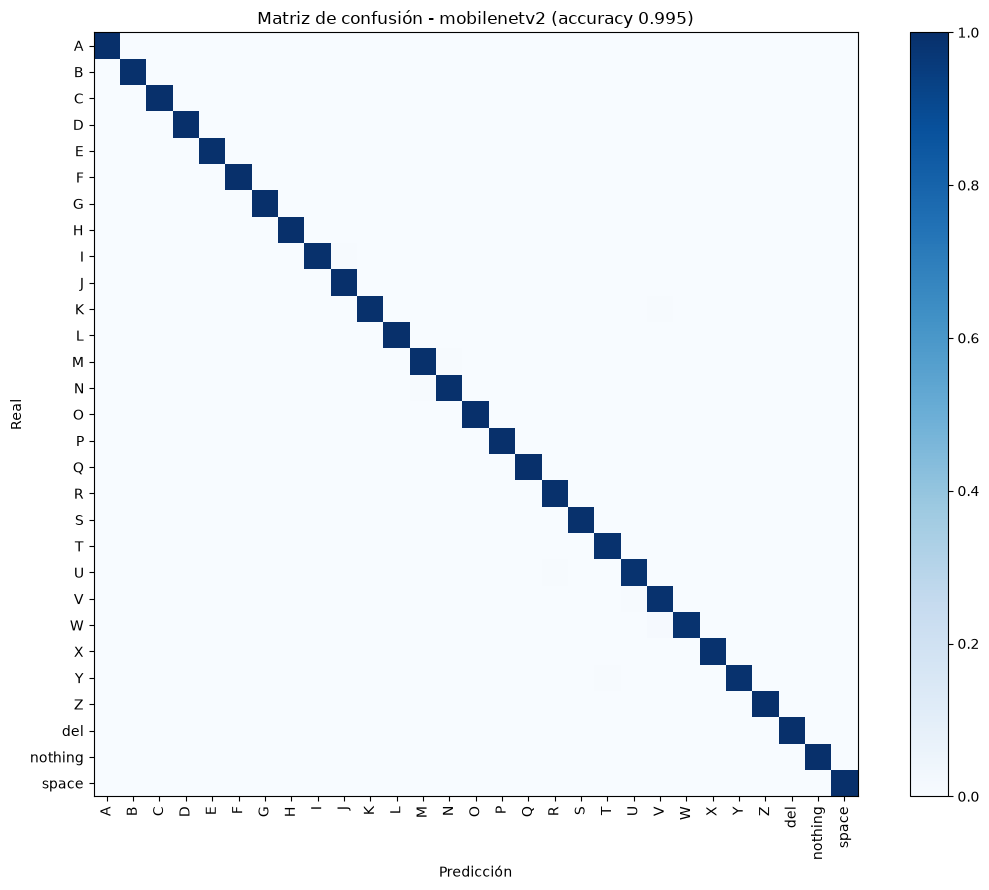

Confusiones más frecuentes en mobilenetv2:
   W -> V: 7 veces
   U -> R: 4 veces
   V -> U: 4 veces
   Y -> T: 4 veces
   M -> N: 4 veces


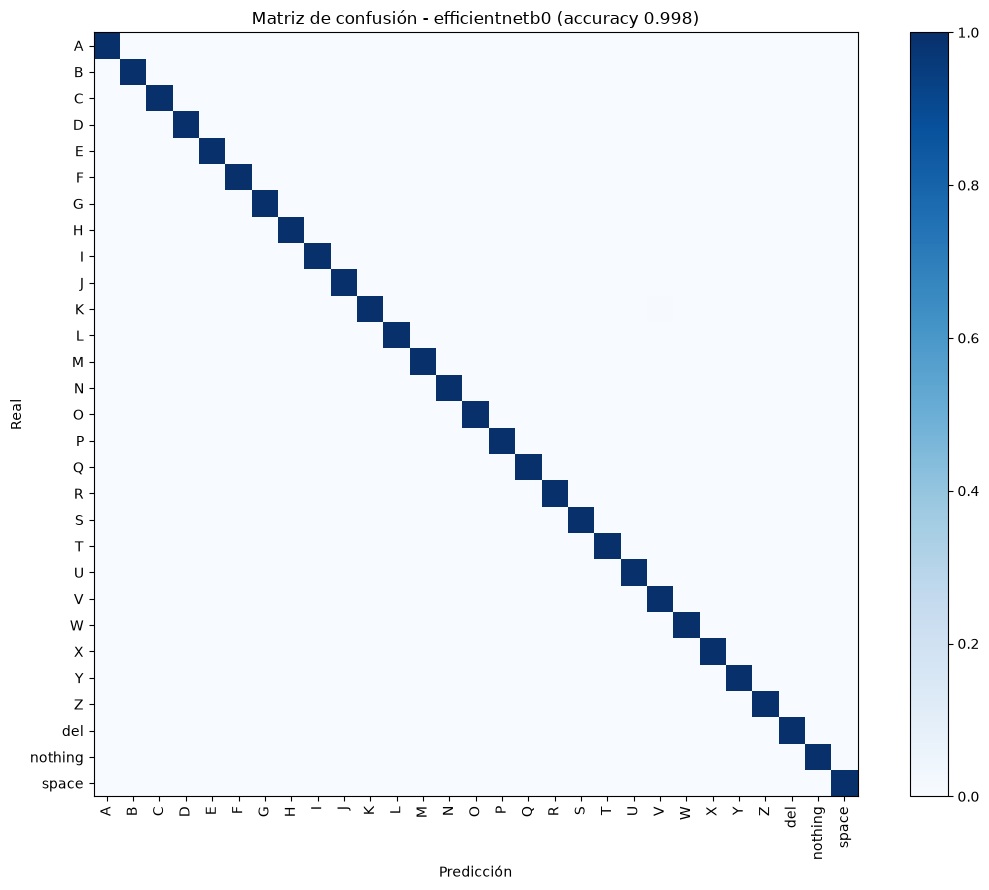

Confusiones más frecuentes en efficientnetb0:
   V -> W: 2 veces
   D -> O: 2 veces
   K -> V: 2 veces
   V -> U: 2 veces
   U -> X: 2 veces


In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import time
from IPython.display import display

MODELOS = ['baseline', 'mobilenetv2', 'efficientnetb0']
class_names = sorted(d for d in os.listdir(DATASET_DIR)
                     if os.path.isdir(os.path.join(DATASET_DIR, d)))
NC = len(class_names)

# 1. Cargar modelos guardados
modelos = {}
for n in MODELOS:
    ruta = f'best_{n}_model.keras'
    if os.path.exists(ruta):
        modelos[n] = tf.keras.models.load_model(ruta)
    else:
        print(f'[WARN] No existe {ruta}, se omite {n}.')

hists = globals().get('histories', {})

# 2. Una sola pasada por el test con los 3 modelos (mismas imágenes para todos)
if 'test_ds' not in globals():
    _, _, test_ds = cargar_datasets_con_split(DATASET_DIR, IMG_SIZE, BATCH_SIZE)

x0, _ = next(iter(test_ds))
for m in modelos.values():          # calentamiento
    m.predict_on_batch(x0)

cms = {n: np.zeros((NC, NC), dtype=np.int64) for n in modelos}
loss_sum = {n: 0.0 for n in modelos}
t_inf = {n: 0.0 for n in modelos}
total = 0
for x, y in test_ds:
    y_true = np.argmax(y.numpy(), axis=1)
    total += len(y_true)
    for n, m in modelos.items():
        t0 = time.perf_counter()
        p = np.asarray(m.predict_on_batch(x), dtype=np.float32)
        t_inf[n] += time.perf_counter() - t0
        loss_sum[n] += float(tf.reduce_sum(tf.keras.losses.categorical_crossentropy(y, p)))
        cms[n] += tf.math.confusion_matrix(y_true, np.argmax(p, axis=1), num_classes=NC).numpy()

# 3. Tabla 1: entrenamiento y validación (en la mejor época según val_accuracy)
filas_train = []
for n in modelos:
    h = hists.get(n)
    if h is None:
        filas_train.append({'Modelo': n}); continue
    b = int(np.argmax(h['val_acc']))
    filas_train.append({
        'Modelo': n,
        'Épocas ejecutadas': len(h['loss']),
        'Mejor época': b + 1,
        'Train accuracy': round(h['acc'][b], 4),
        'Train loss': round(h['loss'][b], 4),
        'Val accuracy': round(h['val_acc'][b], 4),
        'Val loss': round(h['val_loss'][b], 4),
    })
df_train = pd.DataFrame(filas_train)

# 4. Tabla 2: test e inferencia
filas_test = []
for n, cm in cms.items():
    tp = np.diag(cm).astype(float)
    prec = tp / np.maximum(cm.sum(axis=0), 1)
    rec = tp / np.maximum(cm.sum(axis=1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
    filas_test.append({
        'Modelo': n,
        'Test accuracy': round(tp.sum() / cm.sum(), 4),
        'Test loss': round(loss_sum[n] / total, 4),
        'F1 macro': round(f1.mean(), 4),
        'Inferencia (ms/imagen)': round(1000 * t_inf[n] / total, 3),
        'Parámetros (M)': round(modelos[n].count_params() / 1e6, 2),
    })
df_test = pd.DataFrame(filas_test)

print("=== ENTRENAMIENTO Y VALIDACIÓN ===")
display(df_train)
print("\n=== TEST ===")
display(df_test)
df_train.merge(df_test, on='Modelo').to_csv('comparativa_modelos.csv', index=False)

# 5. Matrices de confusión (normalizadas por fila) + confusiones más frecuentes
for n, cm in cms.items():
    cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(11, 9))
    im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(NC)); ax.set_xticklabels(class_names, rotation=90)
    ax.set_yticks(range(NC)); ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
    ax.set_title(f'Matriz de confusión - {n} (accuracy {np.trace(cm)/cm.sum():.3f})')
    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.savefig(f'matriz_confusion_{n}.png', dpi=150)
    plt.show()

    off = cm.copy(); np.fill_diagonal(off, 0)
    print(f"Confusiones más frecuentes en {n}:")
    for k in np.argsort(off.ravel())[::-1][:5]:
        i, j = np.unravel_index(k, off.shape)
        print(f"   {class_names[i]} -> {class_names[j]}: {off[i, j]} veces")

[INFO] 454 fotos en 29 clases.
A          15
B          15
C          15
D          15
E          15
F          15
G          15
H          15
I          15
J          15
K          15
L          15
M          14
N          15
O          15
P          15
Q          15
R          15
S          20
T          20
U          20
V          20
W          20
X          15
Y          15
Z          15
del        15
nothing    15
space      10


/home/uriel/env_dl/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 42 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(store)


[OK] best_baseline_model.keras
[OK] best_mobilenetv2_model.keras
[OK] best_efficientnetb0_model.keras
[INFO] Falta segmentar_mano_con_yolo (celda 4); solo se evalúa "original".

=== RESULTADOS EN MIS FOTOS ===


,Modo,Modelo,Accuracy,Top-3 accuracy,Loss,F1 macro,Fotos
0,original,baseline,0.1432,0.3194,12.5377,0.1191,454
1,original,mobilenetv2,0.5749,0.8348,3.3350,0.5736,454
2,original,efficientnetb0,0.5881,0.8436,2.4989,0.5937,454



=== ACCURACY POR LETRA (recall) ===


,original | baseline,original | mobilenetv2,original | efficientnetb0
A,0.00,0.53,0.47
B,0.00,0.40,1.00
C,0.07,0.47,0.93
D,0.00,0.47,0.60
E,0.00,0.80,0.60
F,0.00,0.13,0.40
G,0.00,0.40,0.13
H,0.07,0.73,0.73
I,0.07,0.27,0.47
J,0.00,0.33,0.60



[INFO] Fotos mal clasificadas guardadas en errores_mis_fotos.csv (769 filas).


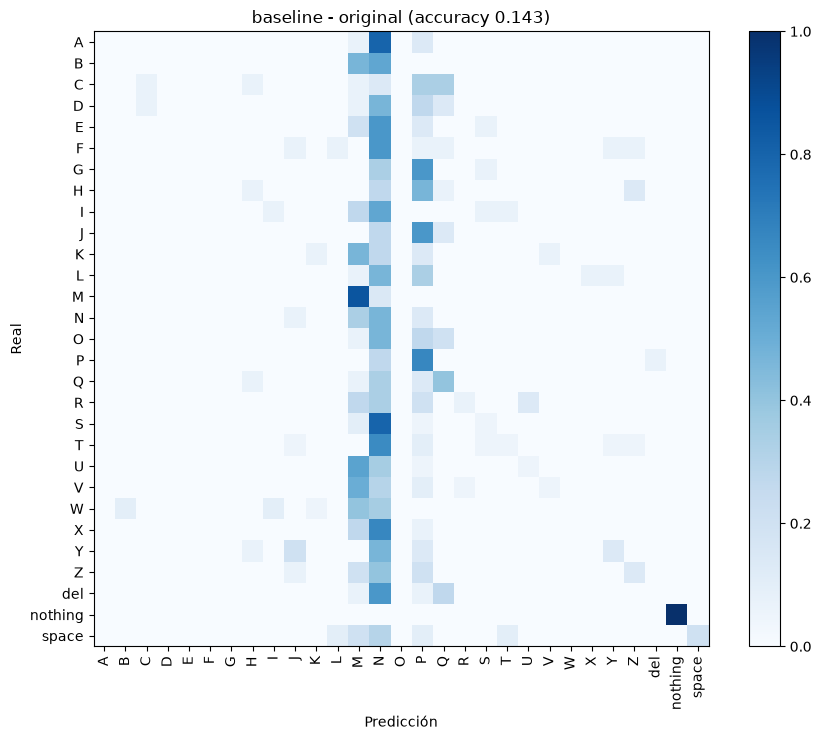

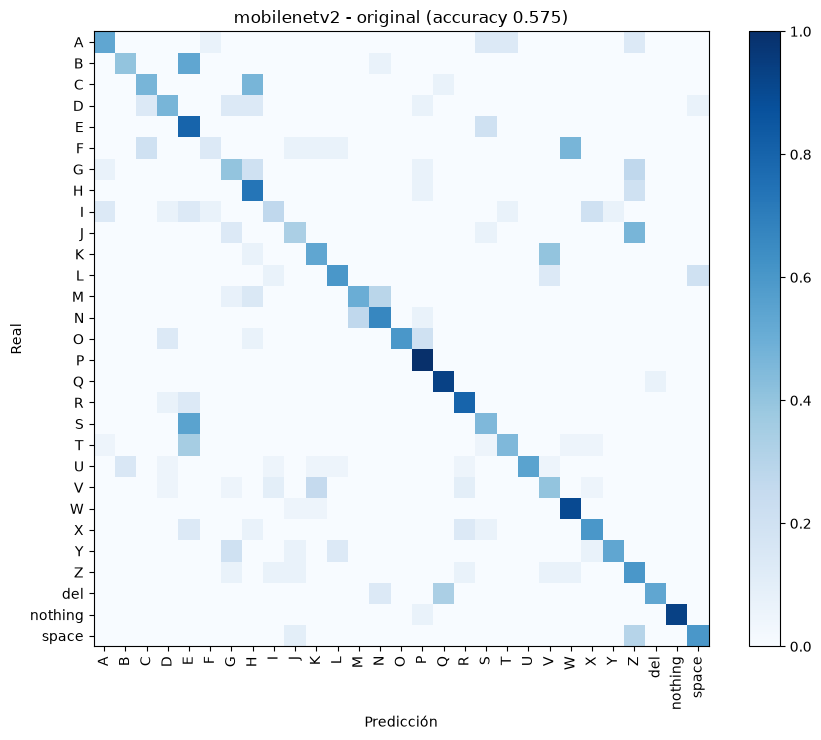

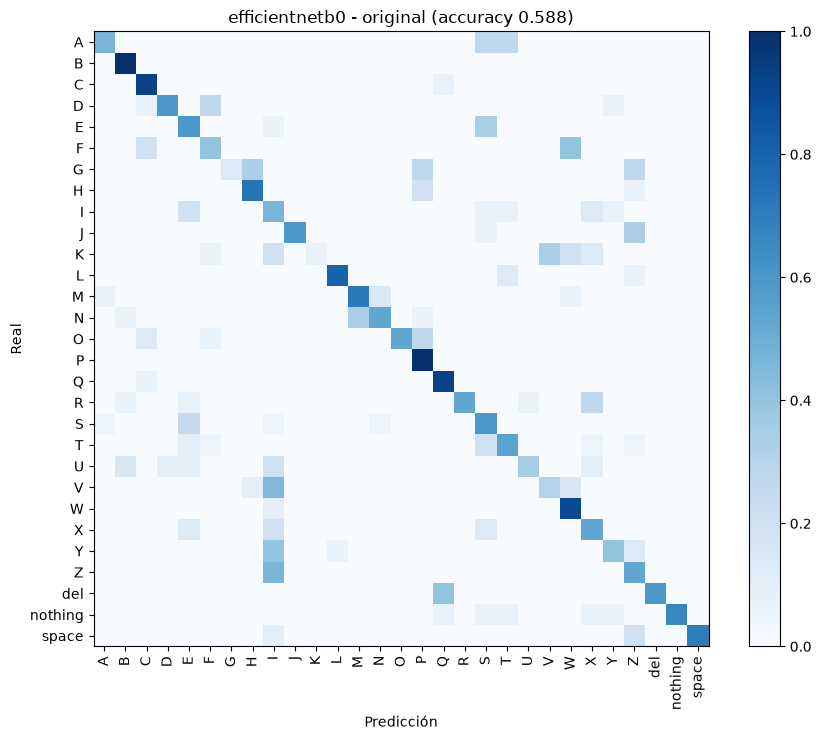

In [13]:
import os
import numpy as np
import pandas as pd
import cv2
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import display

RUTA_FOTOS = './mis_fotos'          # una subcarpeta por letra: A, B, ..., del, nothing, space
MODELOS = ['baseline', 'mobilenetv2', 'efficientnetb0']
EXT = ('.png', '.jpg', '.jpeg', '.bmp', '.webp')
IMG = globals().get('IMG_SIZE', (128, 128))

# Clases en el mismo orden que en entrenamiento
_dir = globals().get('DATASET_DIR', '')
if os.path.isdir(_dir):
    class_names = sorted(d for d in os.listdir(_dir) if os.path.isdir(os.path.join(_dir, d)))
else:
    class_names = list('ABCDEFGHIJKLMNOPQRSTUVWXYZ') + ['del', 'nothing', 'space']
NC = len(class_names)
mapa = {c.lower(): i for i, c in enumerate(class_names)}

# 1. Listar las fotos y sus etiquetas (según el nombre de la carpeta)
rutas, etiquetas = [], []
for carpeta in sorted(os.listdir(RUTA_FOTOS)):
    d = os.path.join(RUTA_FOTOS, carpeta)
    if not os.path.isdir(d):
        continue
    if carpeta.lower() not in mapa:
        print(f'[WARN] La carpeta "{carpeta}" no es una clase conocida; se omite.')
        continue
    for f in sorted(os.listdir(d)):
        if f.lower().endswith(EXT):
            rutas.append(os.path.join(d, f))
            etiquetas.append(mapa[carpeta.lower()])
etiquetas = np.array(etiquetas)
print(f'[INFO] {len(rutas)} fotos en {len(set(etiquetas))} clases.')
print(pd.Series([class_names[i] for i in etiquetas]).value_counts().sort_index().to_string())

# 2. Cargar los modelos entrenados
modelos = {}
for n in MODELOS:
    ruta = f'best_{n}_model.keras'
    if os.path.exists(ruta):
        modelos[n] = tf.keras.models.load_model(ruta)
        print(f'[OK] {ruta}')
    else:
        print(f'[WARN] No existe {ruta}, se omite {n}.')

# 3. Modos de preprocesamiento
MODOS = {'original': False}
if 'segmentar_mano_con_yolo' in globals():
    MODOS['segmentada'] = True
else:
    print('[INFO] Falta segmentar_mano_con_yolo (celda 4); solo se evalúa "original".')

def cargar_imagen(ruta, segmentar):
    img = segmentar_mano_con_yolo(ruta) if segmentar else cv2.imread(ruta)
    if img is None:
        return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return tf.image.resize(img, IMG).numpy()      # mismo remuestreo que en entrenamiento

# 4. Evaluación
resultados, errores, recalls, cms = [], [], {}, {}
for modo, segmentar in MODOS.items():
    imgs, ys, rs = [], [], []
    for r, lab in zip(rutas, etiquetas):
        im = cargar_imagen(r, segmentar)
        if im is None:
            print(f'[WARN] No se pudo leer {r}')
            continue
        imgs.append(im); ys.append(lab); rs.append(r)
    X = np.stack(imgs).astype('float32')
    Y = np.array(ys)
    Y1h = tf.one_hot(Y, NC)

    for n, m in modelos.items():
        p = m.predict(X, batch_size=32, verbose=0).astype('float32')
        pred = p.argmax(axis=1)
        cm = tf.math.confusion_matrix(Y, pred, num_classes=NC).numpy()
        cms[(modo, n)] = cm

        tp = np.diag(cm).astype(float)
        presentes = cm.sum(axis=1) > 0
        prec = tp / np.maximum(cm.sum(axis=0), 1)
        rec = tp / np.maximum(cm.sum(axis=1), 1)
        f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
        top3 = np.mean([Y[i] in np.argsort(p[i])[-3:] for i in range(len(Y))])

        resultados.append({
            'Modo': modo, 'Modelo': n,
            'Accuracy': round((pred == Y).mean(), 4),
            'Top-3 accuracy': round(top3, 4),
            'Loss': round(float(tf.reduce_mean(tf.keras.losses.categorical_crossentropy(Y1h, p))), 4),
            'F1 macro': round(f1[presentes].mean(), 4),
            'Fotos': len(Y),
        })
        recalls[f'{modo} | {n}'] = pd.Series(rec[presentes], index=np.array(class_names)[presentes])
        for i in np.where(pred != Y)[0]:
            errores.append({'Modo': modo, 'Modelo': n, 'Foto': rs[i],
                            'Real': class_names[Y[i]], 'Predicha': class_names[pred[i]]})

# 5. Tablas
df = pd.DataFrame(resultados)
print('\n=== RESULTADOS EN MIS FOTOS ===')
display(df)
print('\n=== ACCURACY POR LETRA (recall) ===')
display(pd.DataFrame(recalls).round(2))
df.to_csv('resultados_mis_fotos.csv', index=False)
pd.DataFrame(errores).to_csv('errores_mis_fotos.csv', index=False)
print(f'\n[INFO] Fotos mal clasificadas guardadas en errores_mis_fotos.csv ({len(errores)} filas).')

# 6. Matrices de confusión (solo las letras que aparecen)
for (modo, n), cm in cms.items():
    idx = np.where((cm.sum(axis=0) + cm.sum(axis=1)) > 0)[0]
    sub = cm[np.ix_(idx, idx)]
    nombres = np.array(class_names)[idx]
    fig, ax = plt.subplots(figsize=(9, 7.5))
    im = ax.imshow(sub / np.maximum(sub.sum(axis=1, keepdims=True), 1), cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(idx))); ax.set_xticklabels(nombres, rotation=90)
    ax.set_yticks(range(len(idx))); ax.set_yticklabels(nombres)
    if len(idx) <= 20:
        for i in range(len(idx)):
            for j in range(len(idx)):
                if sub[i, j]:
                    ax.text(j, i, sub[i, j], ha='center', va='center',
                            color='white' if sub[i, j] / max(sub[i].sum(), 1) > 0.5 else 'black')
    ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
    ax.set_title(f'{n} - {modo} (accuracy {np.trace(cm)/cm.sum():.3f})')
    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.savefig(f'confusion_mis_fotos_{n}_{modo}.png', dpi=150)
    plt.show()

[INFO] Cargando YOLOv8-seg...
[INFO] Segmentación: 457 nuevas, 0 ya existían, 0 con error.


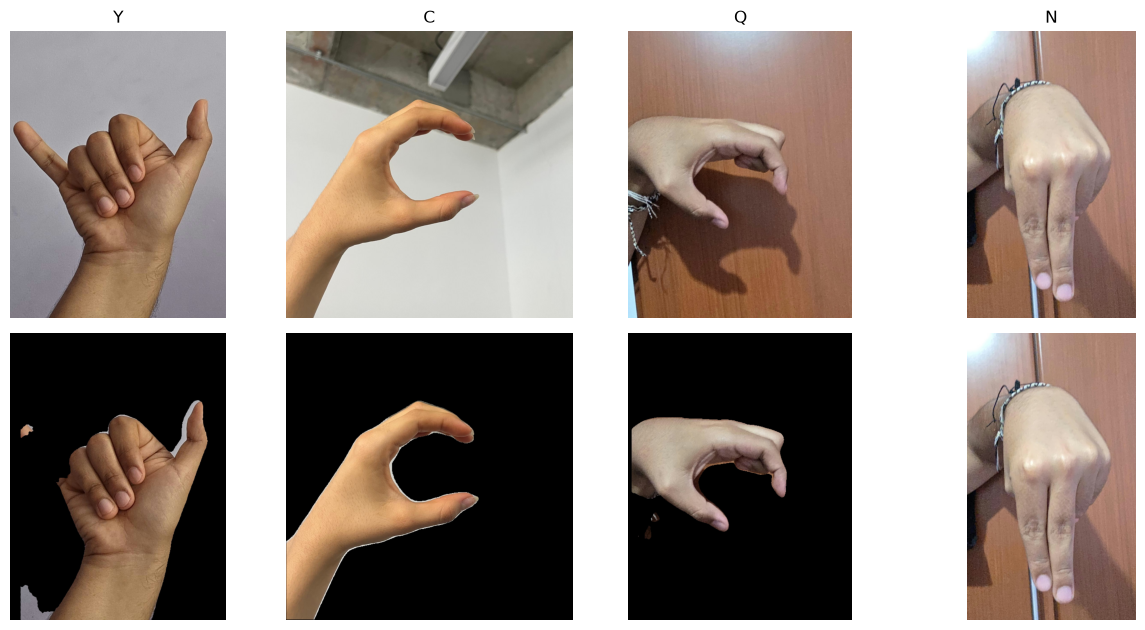

/home/uriel/env_dl/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 42 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(store)


[OK] best_baseline_model.keras
[OK] best_mobilenetv2_model.keras
[OK] best_efficientnetb0_model.keras

[INFO] Conjunto "segmentada": 454 fotos, 29 clases.

[INFO] Conjunto "original": 454 fotos, 29 clases.

=== RESULTADOS EN MIS FOTOS ===


,Conjunto,Modelo,Accuracy,Top-3 accuracy,Loss,F1 macro,Fotos
0,segmentada,baseline,0.1872,0.3877,11.5220,0.1677,454
1,segmentada,mobilenetv2,0.5881,0.8436,3.2172,0.5723,454
2,segmentada,efficientnetb0,0.6740,0.8833,2.1565,0.6792,454
3,original,baseline,0.1432,0.3194,12.5377,0.1191,454
4,original,mobilenetv2,0.5749,0.8348,3.3350,0.5736,454
5,original,efficientnetb0,0.5881,0.8436,2.4989,0.5937,454



=== ACCURACY POR LETRA (recall) ===


,segmentada | baseline,segmentada | mobilenetv2,segmentada | efficientnetb0,original | baseline,original | mobilenetv2,original | efficientnetb0
A,0.00,0.47,0.40,0.00,0.53,0.47
B,0.00,0.67,0.93,0.00,0.40,1.00
C,0.27,0.73,0.93,0.07,0.47,0.93
D,0.00,0.60,0.60,0.00,0.47,0.60
E,0.00,0.60,0.60,0.00,0.80,0.60
F,0.00,0.07,0.33,0.00,0.13,0.40
G,0.00,0.40,0.40,0.00,0.40,0.13
H,0.00,0.60,0.87,0.07,0.73,0.73
I,0.07,0.27,0.47,0.07,0.27,0.47
J,0.00,0.40,0.67,0.00,0.33,0.60



[INFO] 1473 errores guardados en errores_mis_fotos.csv


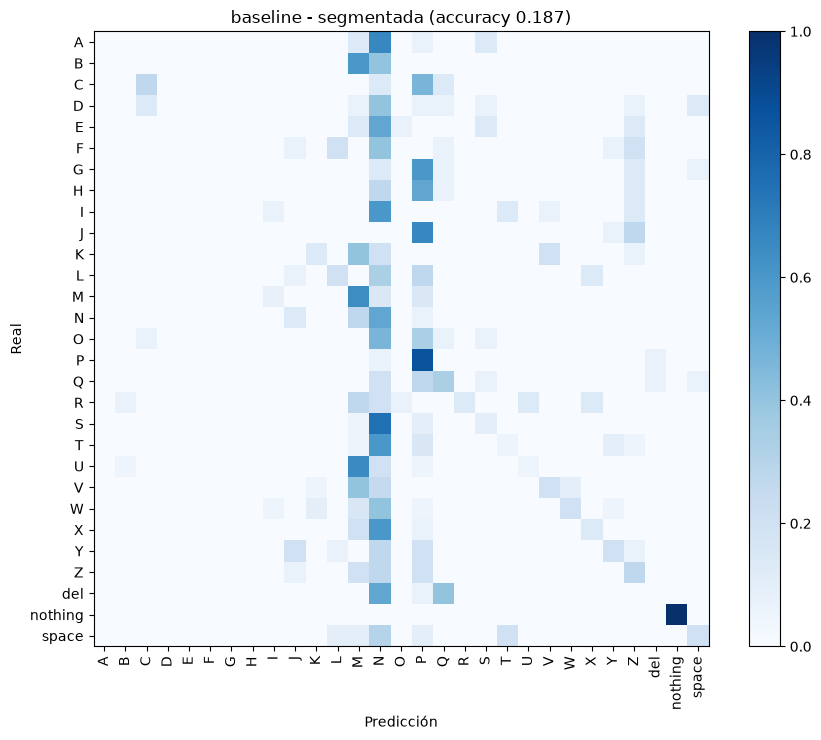

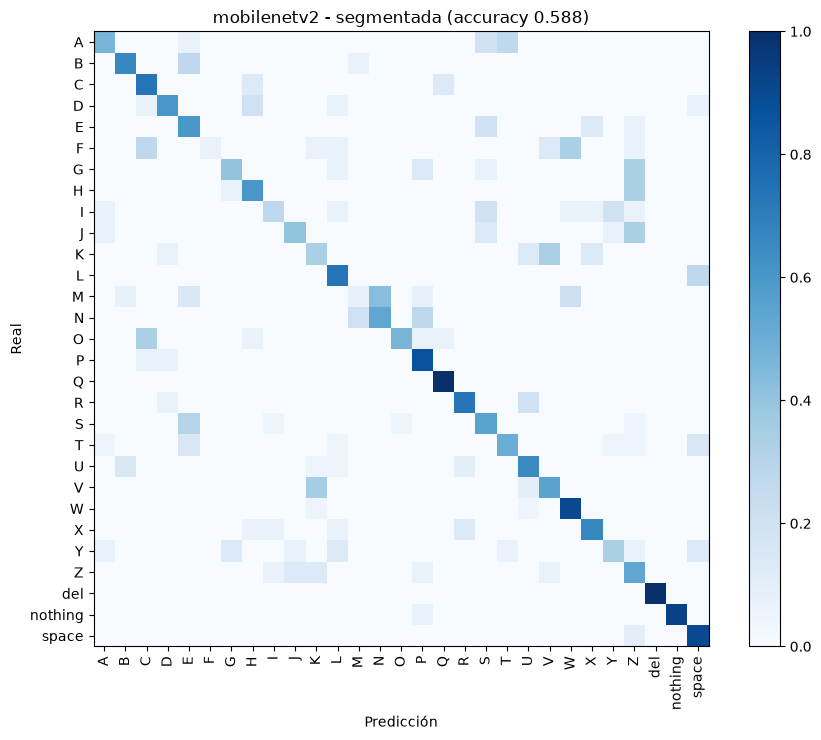

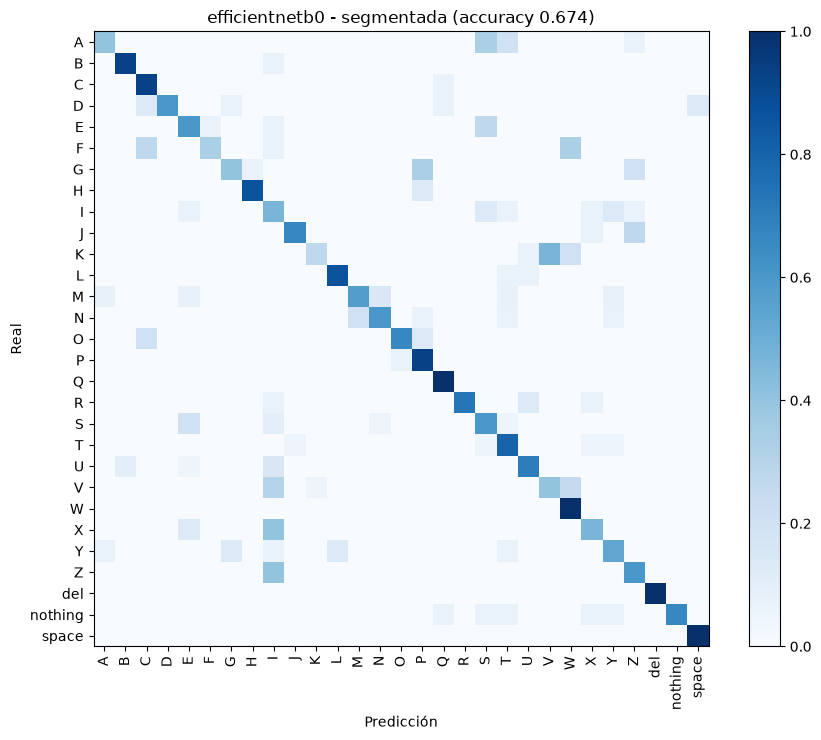

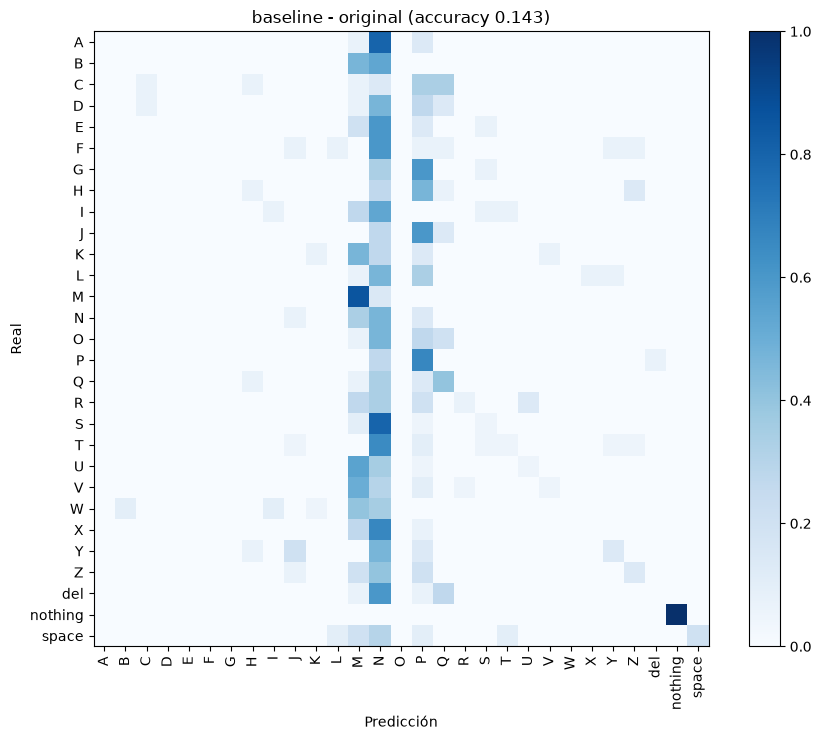

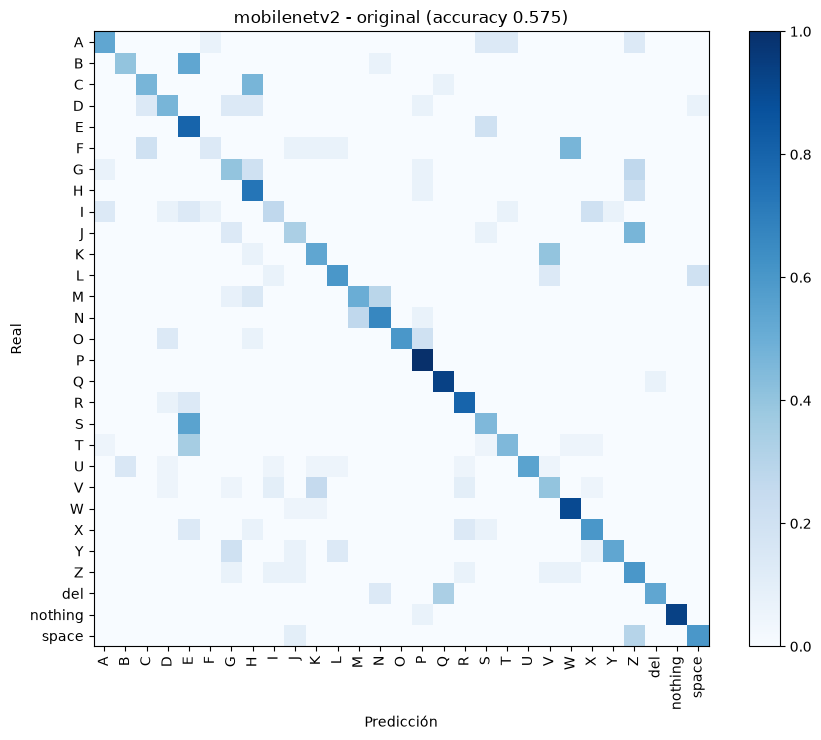

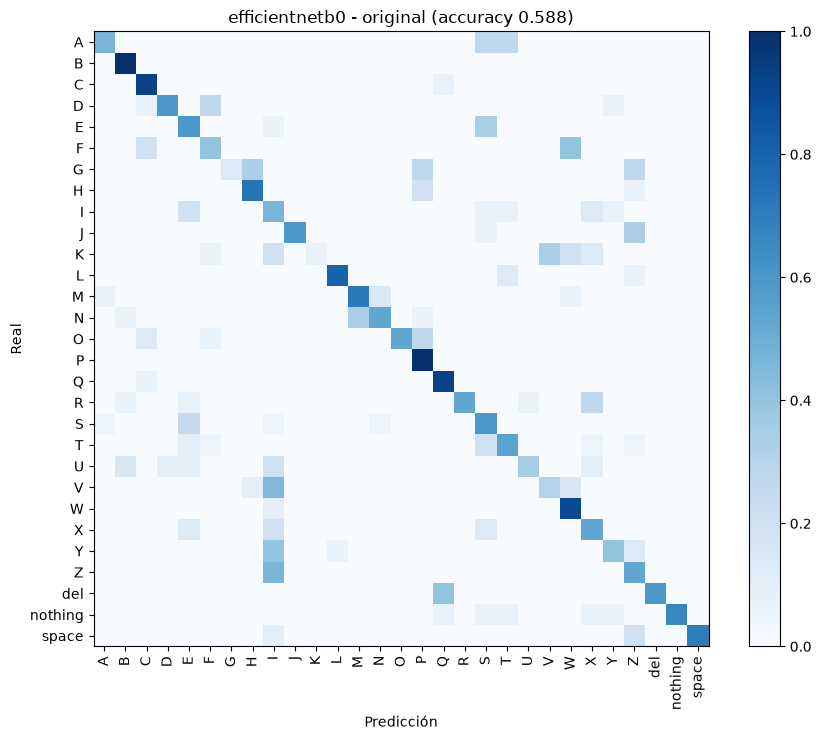

In [14]:
import os
import numpy as np
import pandas as pd
import cv2
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import display

DIR_ORIGEN = './mis_fotos'                    # una subcarpeta por letra
DIR_SEGMENTADAS = './mis_fotos_segmentadas'   # aquí se guardan las fotos segmentadas
REHACER_SEGMENTACION = False                  # True = volver a segmentar aunque ya existan
COMPARAR_CON_ORIGINALES = True                # también evalúa las fotos sin segmentar
MODELOS = ['baseline', 'mobilenetv2', 'efficientnetb0']
EXT = ('.png', '.jpg', '.jpeg', '.bmp', '.webp')
IMG = globals().get('IMG_SIZE', (128, 128))

# Clases en el mismo orden que en entrenamiento
_dir = globals().get('DATASET_DIR', '')
if os.path.isdir(_dir):
    class_names = sorted(d for d in os.listdir(_dir) if os.path.isdir(os.path.join(_dir, d)))
else:
    class_names = list('ABCDEFGHIJKLMNOPQRSTUVWXYZ') + ['del', 'nothing', 'space']
NC = len(class_names)
mapa = {c.lower(): i for i, c in enumerate(class_names)}

# ===================== 1. SEGMENTAR TODAS LAS FOTOS CON YOLO ===================== #
if 'segmentar_mano_con_yolo' not in globals():
    from ultralytics import YOLO
    print('[INFO] Cargando YOLOv8-seg...')
    yolo_model = YOLO('yolov8n-seg.pt')

    def segmentar_mano_con_yolo(image_path):
        img = cv2.imread(image_path)
        if img is None:
            return None
        h, w, _ = img.shape
        results = yolo_model(img, conf=0.15, verbose=False)
        mask_acumulada = np.zeros((h, w), dtype=np.uint8)
        for result in results:
            if result.masks is not None:
                masks = result.masks.data.cpu().numpy()
                classes = result.boxes.cls.cpu().numpy()
                for mask, cls in zip(masks, classes):
                    if int(cls) == 0:  # 'person'
                        m = cv2.resize(mask, (w, h))
                        mask_acumulada = cv2.bitwise_or(mask_acumulada, (m > 0.3).astype(np.uint8) * 255)
        if np.sum(mask_acumulada) == 0:
            return img
        return cv2.bitwise_and(img, img, mask=mask_acumulada)

n_ok = n_omitidas = n_fallo = 0
for raiz, _, archivos in os.walk(DIR_ORIGEN):
    for f in sorted(archivos):
        if not f.lower().endswith(EXT):
            continue
        origen = os.path.join(raiz, f)
        destino = os.path.join(DIR_SEGMENTADAS, os.path.relpath(origen, DIR_ORIGEN))
        if os.path.exists(destino) and not REHACER_SEGMENTACION:
            n_omitidas += 1
            continue
        os.makedirs(os.path.dirname(destino), exist_ok=True)
        img = segmentar_mano_con_yolo(origen)
        if img is None:
            n_fallo += 1
            print(f'[WARN] No se pudo leer {origen}')
            continue
        cv2.imwrite(destino, img)
        n_ok += 1
print(f'[INFO] Segmentación: {n_ok} nuevas, {n_omitidas} ya existían, {n_fallo} con error.')

# Comprobación visual: original vs segmentada (hasta 4 ejemplos)
ejemplos = []
for raiz, _, archivos in os.walk(DIR_ORIGEN):
    for f in sorted(archivos):
        if f.lower().endswith(EXT):
            ejemplos.append(os.path.join(raiz, f))
ejemplos = ejemplos[::max(1, len(ejemplos) // 4)][:4]
if ejemplos:
    fig, axs = plt.subplots(2, len(ejemplos), figsize=(3.2 * len(ejemplos), 6.4), squeeze=False)
    for k, o in enumerate(ejemplos):
        s = os.path.join(DIR_SEGMENTADAS, os.path.relpath(o, DIR_ORIGEN))
        for fila, ruta in enumerate((o, s)):
            im = cv2.imread(ruta)
            if im is not None:
                axs[fila, k].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
            axs[fila, k].axis('off')
        axs[0, k].set_title(os.path.basename(os.path.dirname(o)))
    axs[0, 0].set_ylabel('Original'); axs[1, 0].set_ylabel('Segmentada')
    plt.tight_layout(); plt.show()

# ===================== 2. CARGAR MODELOS ENTRENADOS ===================== #
modelos = {}
for n in MODELOS:
    ruta = f'best_{n}_model.keras'
    if os.path.exists(ruta):
        modelos[n] = tf.keras.models.load_model(ruta)
        print(f'[OK] {ruta}')
    else:
        print(f'[WARN] No existe {ruta}, se omite {n}.')

# ===================== 3. EVALUAR ===================== #
def listar_fotos(base):
    rutas, ys = [], []
    for carpeta in sorted(os.listdir(base)):
        d = os.path.join(base, carpeta)
        if not os.path.isdir(d):
            continue
        if carpeta.lower() not in mapa:
            print(f'[WARN] La carpeta "{carpeta}" no es una clase conocida; se omite.')
            continue
        for f in sorted(os.listdir(d)):
            if f.lower().endswith(EXT):
                rutas.append(os.path.join(d, f)); ys.append(mapa[carpeta.lower()])
    return rutas, np.array(ys)

def cargar(ruta):
    img = cv2.imread(ruta)
    if img is None:
        return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return tf.image.resize(img, IMG).numpy()      # mismo remuestreo que en entrenamiento

CONJUNTOS = {'segmentada': DIR_SEGMENTADAS}
if COMPARAR_CON_ORIGINALES:
    CONJUNTOS['original'] = DIR_ORIGEN

resultados, errores, recalls, cms = [], [], {}, {}
for nombre_set, base in CONJUNTOS.items():
    rutas, etiquetas = listar_fotos(base)
    imgs, ys, rs = [], [], []
    for r, lab in zip(rutas, etiquetas):
        im = cargar(r)
        if im is None:
            print(f'[WARN] No se pudo leer {r}'); continue
        imgs.append(im); ys.append(lab); rs.append(r)
    X = np.stack(imgs).astype('float32'); Y = np.array(ys)
    Y1h = tf.one_hot(Y, NC)
    print(f'\n[INFO] Conjunto "{nombre_set}": {len(Y)} fotos, {len(set(Y))} clases.')

    for n, m in modelos.items():
        p = m.predict(X, batch_size=32, verbose=0).astype('float32')
        pred = p.argmax(axis=1)
        cm = tf.math.confusion_matrix(Y, pred, num_classes=NC).numpy()
        cms[(nombre_set, n)] = cm

        tp = np.diag(cm).astype(float)
        presentes = cm.sum(axis=1) > 0
        prec = tp / np.maximum(cm.sum(axis=0), 1)
        rec = tp / np.maximum(cm.sum(axis=1), 1)
        f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
        top3 = np.mean([Y[i] in np.argsort(p[i])[-3:] for i in range(len(Y))])

        resultados.append({
            'Conjunto': nombre_set, 'Modelo': n,
            'Accuracy': round((pred == Y).mean(), 4),
            'Top-3 accuracy': round(top3, 4),
            'Loss': round(float(tf.reduce_mean(tf.keras.losses.categorical_crossentropy(Y1h, p))), 4),
            'F1 macro': round(f1[presentes].mean(), 4),
            'Fotos': len(Y),
        })
        recalls[f'{nombre_set} | {n}'] = pd.Series(rec[presentes], index=np.array(class_names)[presentes])
        for i in np.where(pred != Y)[0]:
            errores.append({'Conjunto': nombre_set, 'Modelo': n, 'Foto': rs[i],
                            'Real': class_names[Y[i]], 'Predicha': class_names[pred[i]]})

# ===================== 4. TABLAS ===================== #
df = pd.DataFrame(resultados)
print('\n=== RESULTADOS EN MIS FOTOS ===')
display(df)
print('\n=== ACCURACY POR LETRA (recall) ===')
display(pd.DataFrame(recalls).round(2))
df.to_csv('resultados_mis_fotos.csv', index=False)
pd.DataFrame(errores).to_csv('errores_mis_fotos.csv', index=False)
print(f'\n[INFO] {len(errores)} errores guardados en errores_mis_fotos.csv')

# ===================== 5. MATRICES DE CONFUSIÓN ===================== #
for (nombre_set, n), cm in cms.items():
    idx = np.where((cm.sum(axis=0) + cm.sum(axis=1)) > 0)[0]
    sub = cm[np.ix_(idx, idx)]
    nombres = np.array(class_names)[idx]
    fig, ax = plt.subplots(figsize=(9, 7.5))
    im = ax.imshow(sub / np.maximum(sub.sum(axis=1, keepdims=True), 1), cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(idx))); ax.set_xticklabels(nombres, rotation=90)
    ax.set_yticks(range(len(idx))); ax.set_yticklabels(nombres)
    if len(idx) <= 20:
        for i in range(len(idx)):
            for j in range(len(idx)):
                if sub[i, j]:
                    ax.text(j, i, sub[i, j], ha='center', va='center',
                            color='white' if sub[i, j] / max(sub[i].sum(), 1) > 0.5 else 'black')
    ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
    ax.set_title(f'{n} - {nombre_set} (accuracy {np.trace(cm)/cm.sum():.3f})')
    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.savefig(f'confusion_mis_fotos_{n}_{nombre_set}.png', dpi=150)
    plt.show()